# Lab 1 - Phần 1.2: Xử lý dữ liệu & Trực quan hóa
**Nội dung:** bài mẫu (giá nhà Amsterdam) + Bài tập 1 (Red Wine) + Bài tập 2 (Diabetes, Online Retail).

**Dữ liệu:** `HousingPrices.csv`, `winequality-red.csv`, `diabetes.csv`, `OnlineRetail.csv` (hoặc `Online Retail.xlsx`)

In [1]:
import sys; sys.path.append(".")
from utils import *

## A. Bài làm mẫu - Giá nhà Amsterdam (matplotlib / seaborn)

In [2]:
house = load_table("HousingPrices.csv", "HousingPricesData.csv", "*housing*.csv", "*house*.csv")
house = house.drop(columns=[c for c in house.columns if c.lower().startswith("unnamed")], errors="ignore")
overview(house, "Amsterdam housing")
house = house.dropna(subset=["Price"])

[Đọc dữ liệu] data\HousingPrices-Amsterdam-August-2021.csv
===== Amsterdam housing =====
Kích thước: 924 dòng x 7 cột
Số dòng trùng lặp: 1


,dtype,missing,missing_%,n_unique
Address,object,0,0.00,919
Zip,object,0,0.00,834
Price,float64,4,0.43,226
Area,int64,0,0.00,193
Room,int64,0,0.00,13
Lon,float64,0,0.00,894
Lat,float64,0,0.00,886


,Address,Zip,Price,Area,Room,Lon,Lat
0,"Blasiusstraat 8 2, Amsterdam",1091 CR,685000.0,64,3,4.907736,52.356157
1,"Kromme Leimuidenstraat 13 H, Amsterdam",1059 EL,475000.0,60,3,4.850476,52.348586
2,"Zaaiersweg 11 A, Amsterdam",1097 SM,850000.0,109,4,4.944774,52.343782
3,"Tenerifestraat 40, Amsterdam",1060 TH,580000.0,128,6,4.789928,52.343712
4,"Winterjanpad 21, Amsterdam",1036 KN,720000.0,138,5,4.902503,52.410538


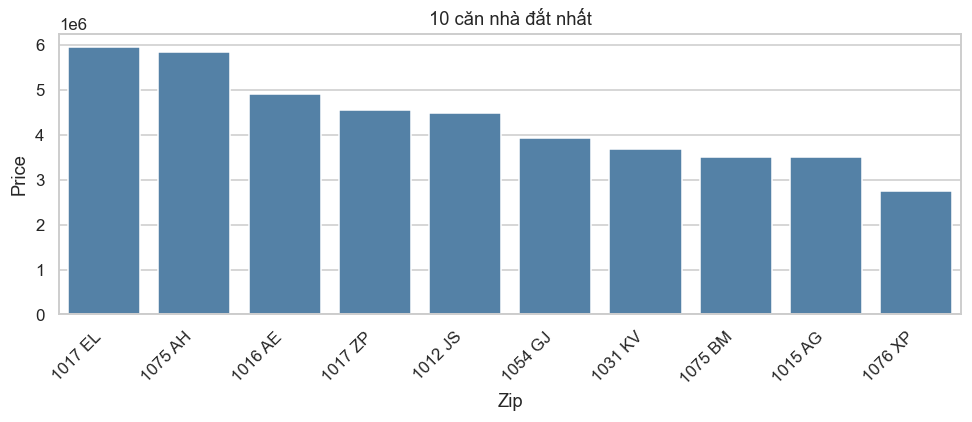

[Đã lưu] figures\s12_house_top10.png


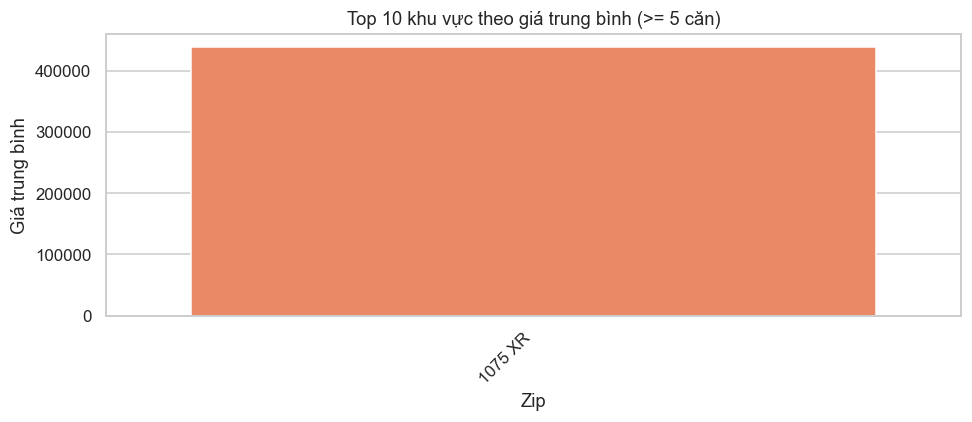

[Đã lưu] figures\s12_house_zip_mean.png


In [3]:
# Cách 1 (theo đề): 10 căn đắt nhất
top10 = house.sort_values("Price", ascending=False).head(10)
plt.figure(figsize=(9, 4))
sns.barplot(data=top10, x="Zip", y="Price", order=top10["Zip"], color="steelblue")
plt.xticks(rotation=45, ha="right"); plt.title("10 căn nhà đắt nhất")
save_fig("s12_house_top10")

# Cách 2: giá trung bình theo khu vực (Zip) - có ý nghĩa thống kê hơn
zip_mean = house.groupby("Zip")["Price"].agg(["mean", "count"]).query("count >= 5").sort_values("mean", ascending=False).head(10)
plt.figure(figsize=(9, 4)); sns.barplot(x=zip_mean.index, y=zip_mean["mean"], color="coral")
plt.xticks(rotation=45, ha="right"); plt.ylabel("Giá trung bình"); plt.title("Top 10 khu vực theo giá trung bình (>= 5 căn)")
save_fig("s12_house_zip_mean")

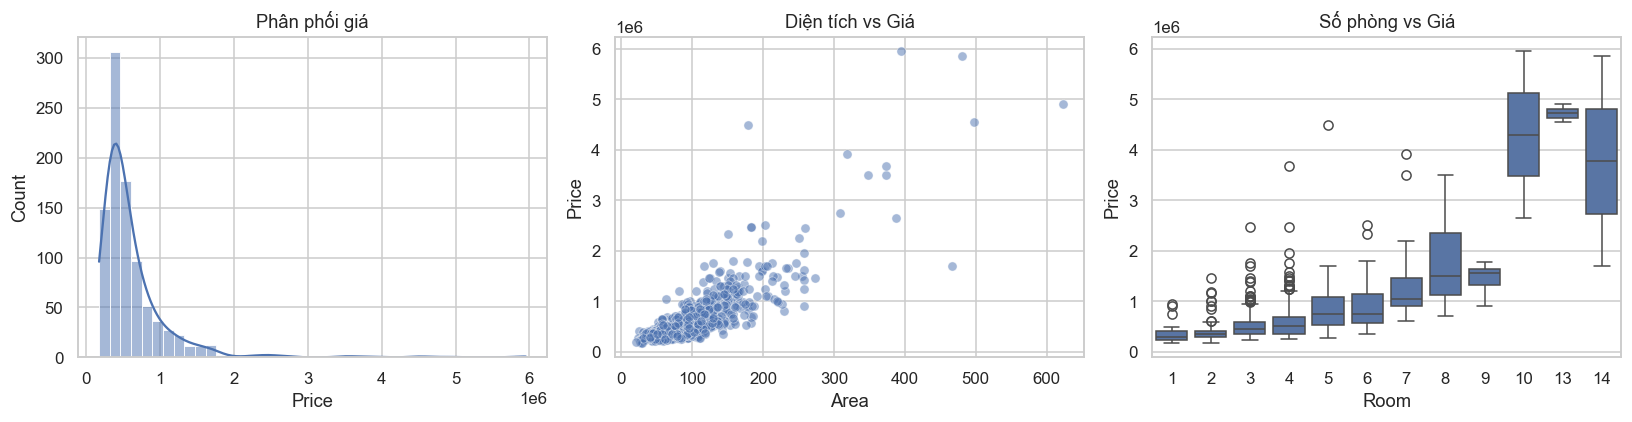

[Đã lưu] figures\s12_house_overview.png


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(house["Price"], bins=40, kde=True, ax=axs[0]); axs[0].set_title("Phân phối giá")
sns.scatterplot(data=house, x="Area", y="Price", alpha=.5, ax=axs[1]); axs[1].set_title("Diện tích vs Giá")
sns.boxplot(data=house, x="Room", y="Price", ax=axs[2]); axs[2].set_title("Số phòng vs Giá")
save_fig("s12_house_overview")

## B. Bài tập 1 - Red Wine Quality: trực quan hóa

In [5]:
wine = load_table("winequality-red.csv", "*wine*red*.csv", "winequality*.csv", "*wine*.csv").drop_duplicates()
feat = [c for c in wine.columns if c != "quality"]
overview(wine, "Red Wine")

[Đọc dữ liệu] data\winequality-red.csv
===== Red Wine =====
Kích thước: 1359 dòng x 12 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
fixed acidity,float64,0,0.0,96
volatile acidity,float64,0,0.0,143
citric acid,float64,0,0.0,80
residual sugar,float64,0,0.0,91
chlorides,float64,0,0.0,153
free sulfur dioxide,float64,0,0.0,60
total sulfur dioxide,float64,0,0.0,144
density,float64,0,0.0,436
pH,float64,0,0.0,89
sulphates,float64,0,0.0,96


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


**1. Phân phối biến mục tiêu và từng thuộc tính**

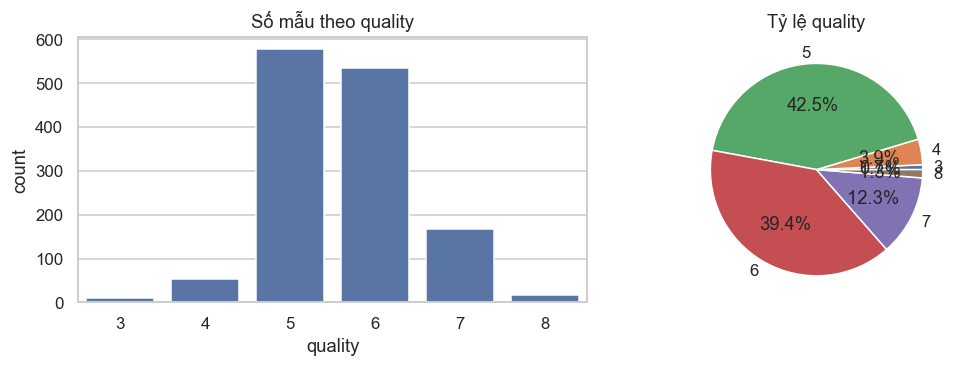

[Đã lưu] figures\s12_wine_quality.png


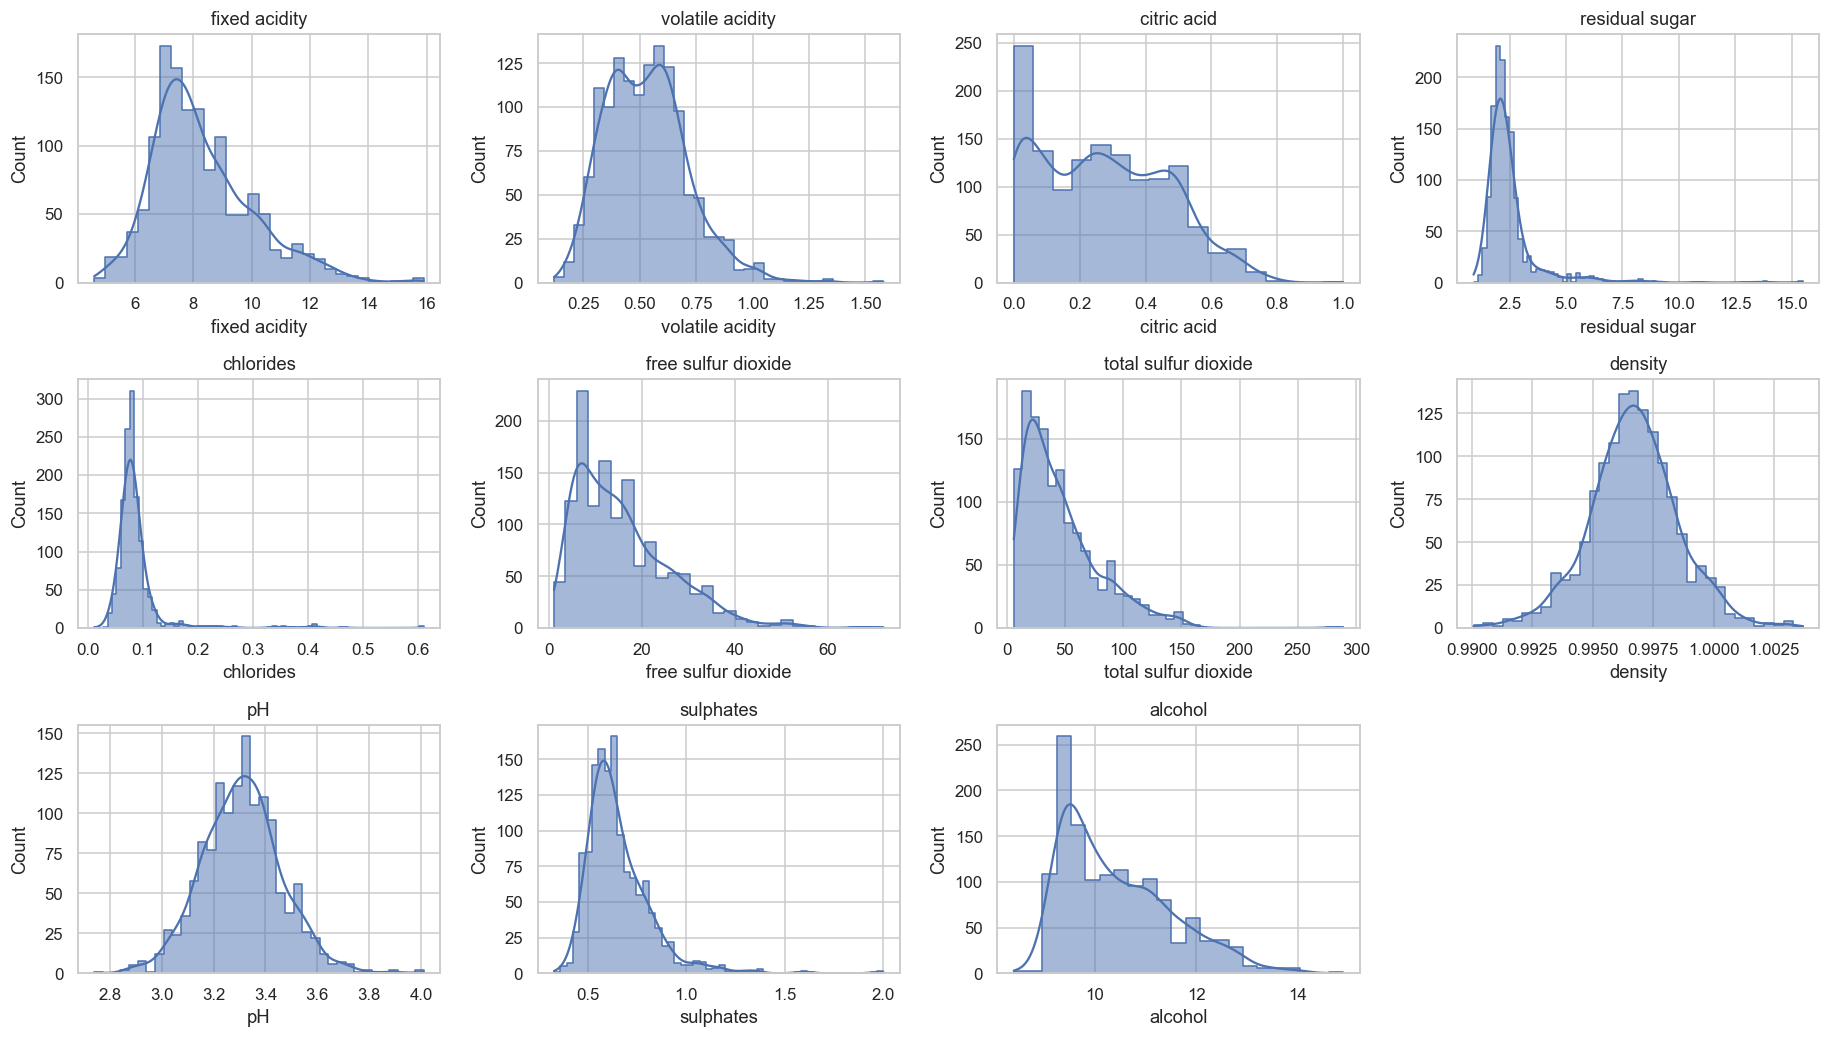

[Đã lưu] figures\s12_wine_hist.png


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(data=wine, x="quality", ax=axs[0]); axs[0].set_title("Số mẫu theo quality")
wine["quality"].value_counts().sort_index().plot.pie(autopct="%1.1f%%", ax=axs[1], ylabel="")
axs[1].set_title("Tỷ lệ quality")
save_fig("s12_wine_quality")

grid_plot(wine, feat, kind="hist", ncols=4, name="s12_wine_hist")

**2. Quan hệ thuộc tính - chất lượng (boxplot / violin)**

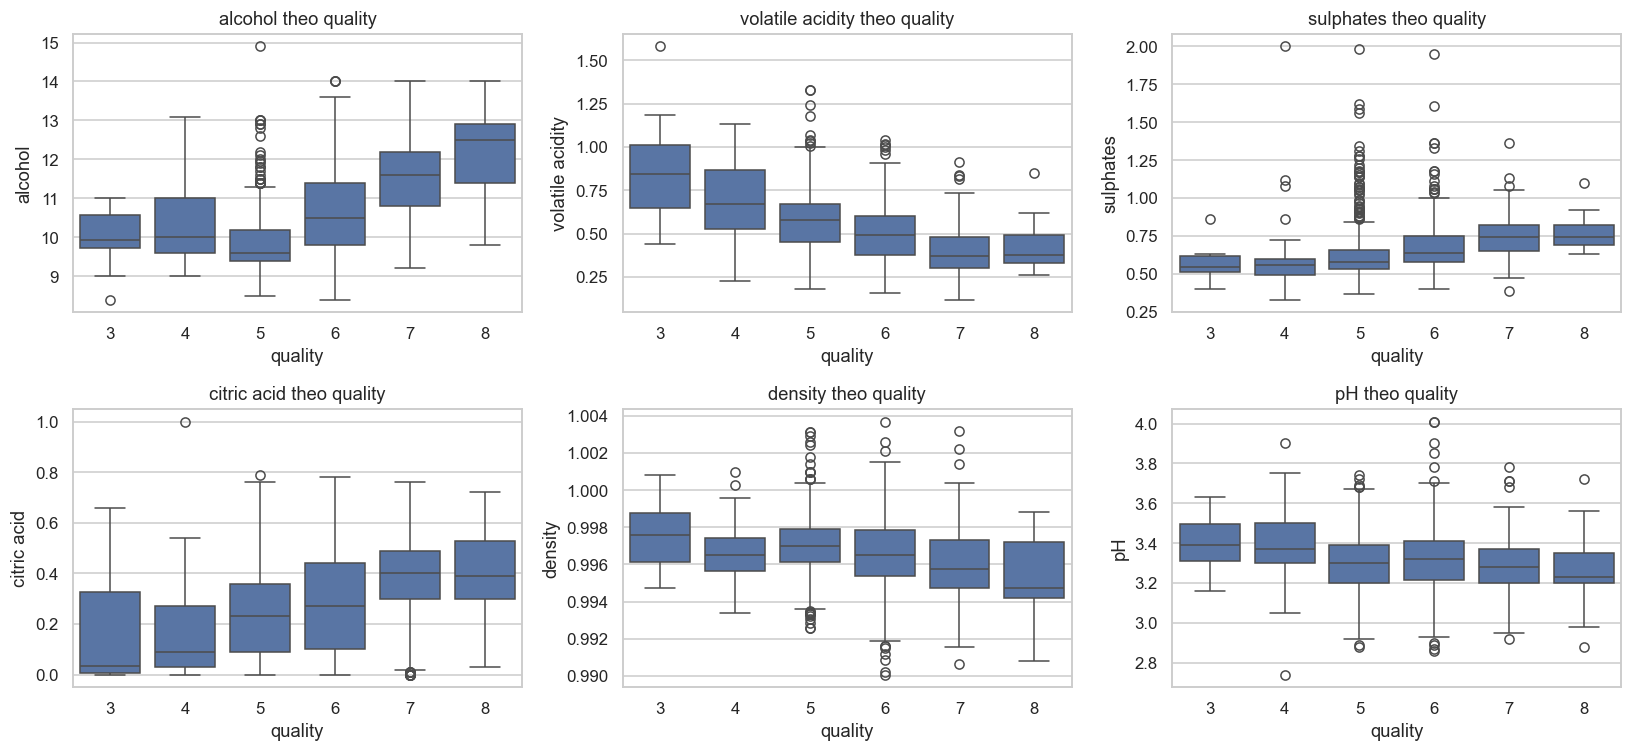

[Đã lưu] figures\s12_wine_box_quality.png


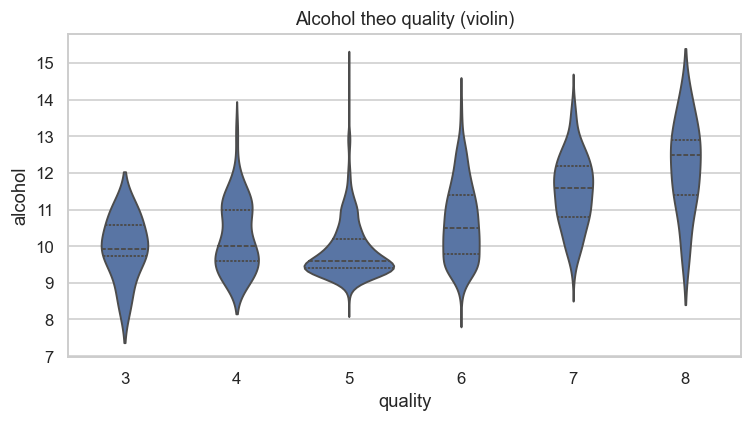

[Đã lưu] figures\s12_wine_violin_alcohol.png


In [7]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axs.ravel(), ["alcohol", "volatile acidity", "sulphates", "citric acid", "density", "pH"]):
    if c in wine.columns:
        sns.boxplot(data=wine, x="quality", y=c, ax=ax); ax.set_title(f"{c} theo quality")
save_fig("s12_wine_box_quality")

plt.figure(figsize=(7, 4)); sns.violinplot(data=wine, x="quality", y="alcohol", inner="quartile")
plt.title("Alcohol theo quality (violin)"); save_fig("s12_wine_violin_alcohol")

**3. Tương quan giữa các biến**

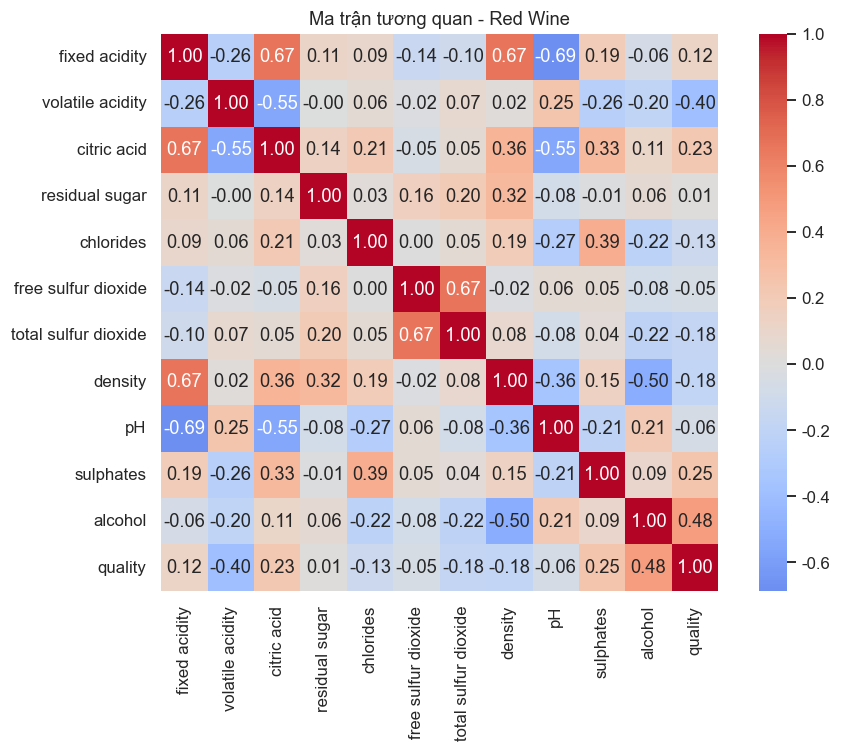

[Đã lưu] figures\s12_wine_corr.png
Tương quan với quality (giảm dần theo |r|):


,corr
alcohol,0.480
volatile acidity,-0.395
sulphates,0.249
citric acid,0.228
density,-0.184
total sulfur dioxide,-0.178
chlorides,-0.131
fixed acidity,0.119
pH,-0.055
free sulfur dioxide,-0.050


In [8]:
corr = wine.corr(numeric_only=True)
plt.figure(figsize=(9, 7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Ma trận tương quan - Red Wine"); save_fig("s12_wine_corr")
print("Tương quan với quality (giảm dần theo |r|):")
display(corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3).to_frame("corr"))

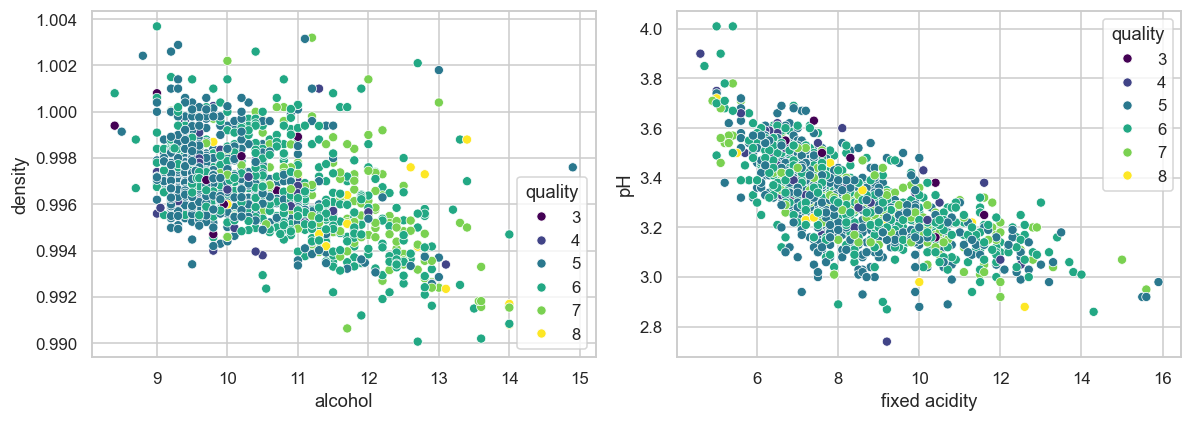

[Đã lưu] figures\s12_wine_scatter.png


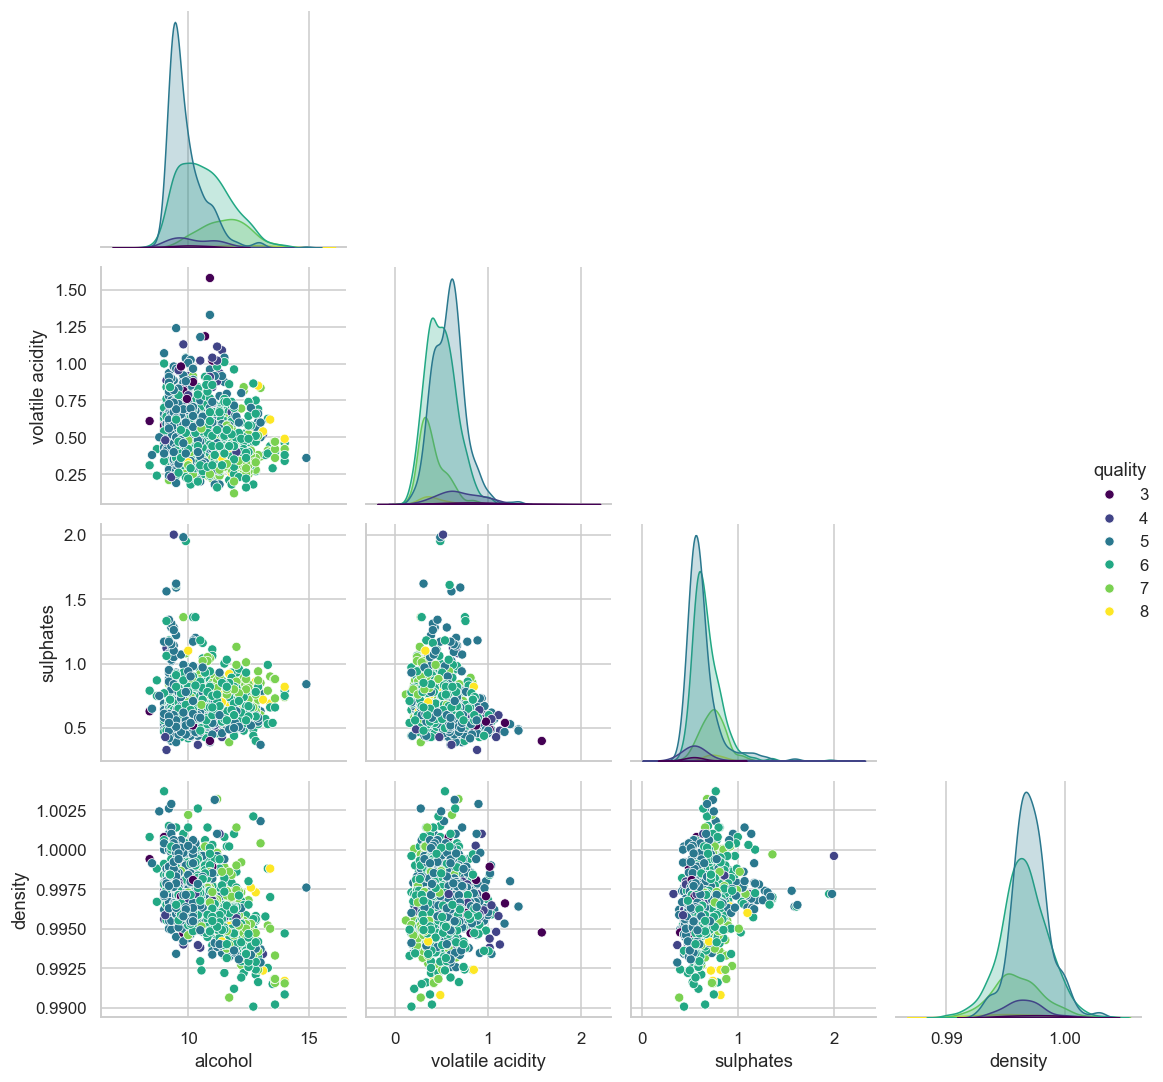

[Đã lưu] figures\s12_wine_pairplot.png


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=wine, x="alcohol", y="density", hue="quality", palette="viridis", ax=axs[0])
sns.scatterplot(data=wine, x="fixed acidity", y="pH", hue="quality", palette="viridis", ax=axs[1])
save_fig("s12_wine_scatter")
sns.pairplot(wine[["alcohol", "volatile acidity", "sulphates", "density", "quality"]], hue="quality", palette="viridis", corner=True)
save_fig("s12_wine_pairplot")

In [10]:
# Biểu đồ tương tác (nếu đã cài plotly): lưu HTML vào outputs/
try:
    import plotly.express as px
    fig = px.scatter(wine, x="alcohol", y="volatile acidity", color=wine["quality"].astype(str), title="Wine: alcohol vs volatile acidity")
    fig.write_html(OUT_DIR / "wine_scatter_interactive.html")
    print("Đã lưu outputs/wine_scatter_interactive.html")
except ImportError:
    print("Chưa cài plotly (pip install plotly) - bỏ qua biểu đồ tương tác")

Đã lưu outputs/wine_scatter_interactive.html


## C. Bài tập 2.1 - Pima Diabetes: trực quan hóa & EDA

In [11]:
db, target = load_diabetes(clean_zeros=True)      # 0 -> NaN ở các cột y khoa
feat_db = [c for c in db.columns if c != target]
db["Outcome_label"] = db[target].map({0: "Không bệnh", 1: "Có bệnh"})
overview(db.drop(columns="Outcome_label"), "Diabetes")

[Đọc dữ liệu] data\diabetes.csv
===== Diabetes =====
Kích thước: 768 dòng x 9 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
Pregnancies,int64,0,0.00,17
Glucose,float64,5,0.65,135
BloodPressure,float64,35,4.56,46
SkinThickness,float64,227,29.56,50
Insulin,float64,374,48.70,185
BMI,float64,11,1.43,247
DiabetesPedigreeFunction,float64,0,0.00,517
Age,int64,0,0.00,52
Outcome,int64,0,0.00,2


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


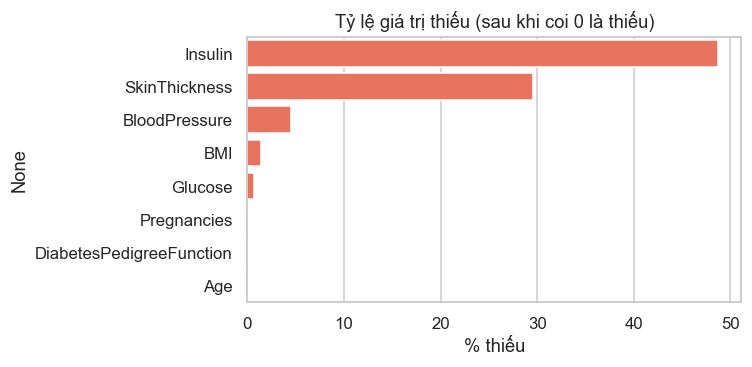

[Đã lưu] figures\s12_diabetes_missing.png


In [12]:
# Giá trị thiếu
miss = db[feat_db].isna().mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(7, 3.5)); sns.barplot(x=miss.values, y=miss.index, color="tomato")
plt.xlabel("% thiếu"); plt.title("Tỷ lệ giá trị thiếu (sau khi coi 0 là thiếu)")
save_fig("s12_diabetes_missing")

# Điền thiếu bằng median theo nhóm
for c in feat_db:
    db[c] = db[c].fillna(db.groupby(target)[c].transform("median"))

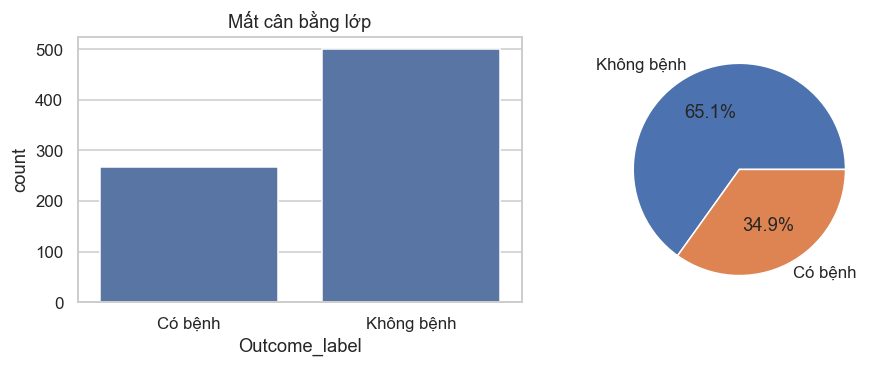

[Đã lưu] figures\s12_diabetes_outcome.png


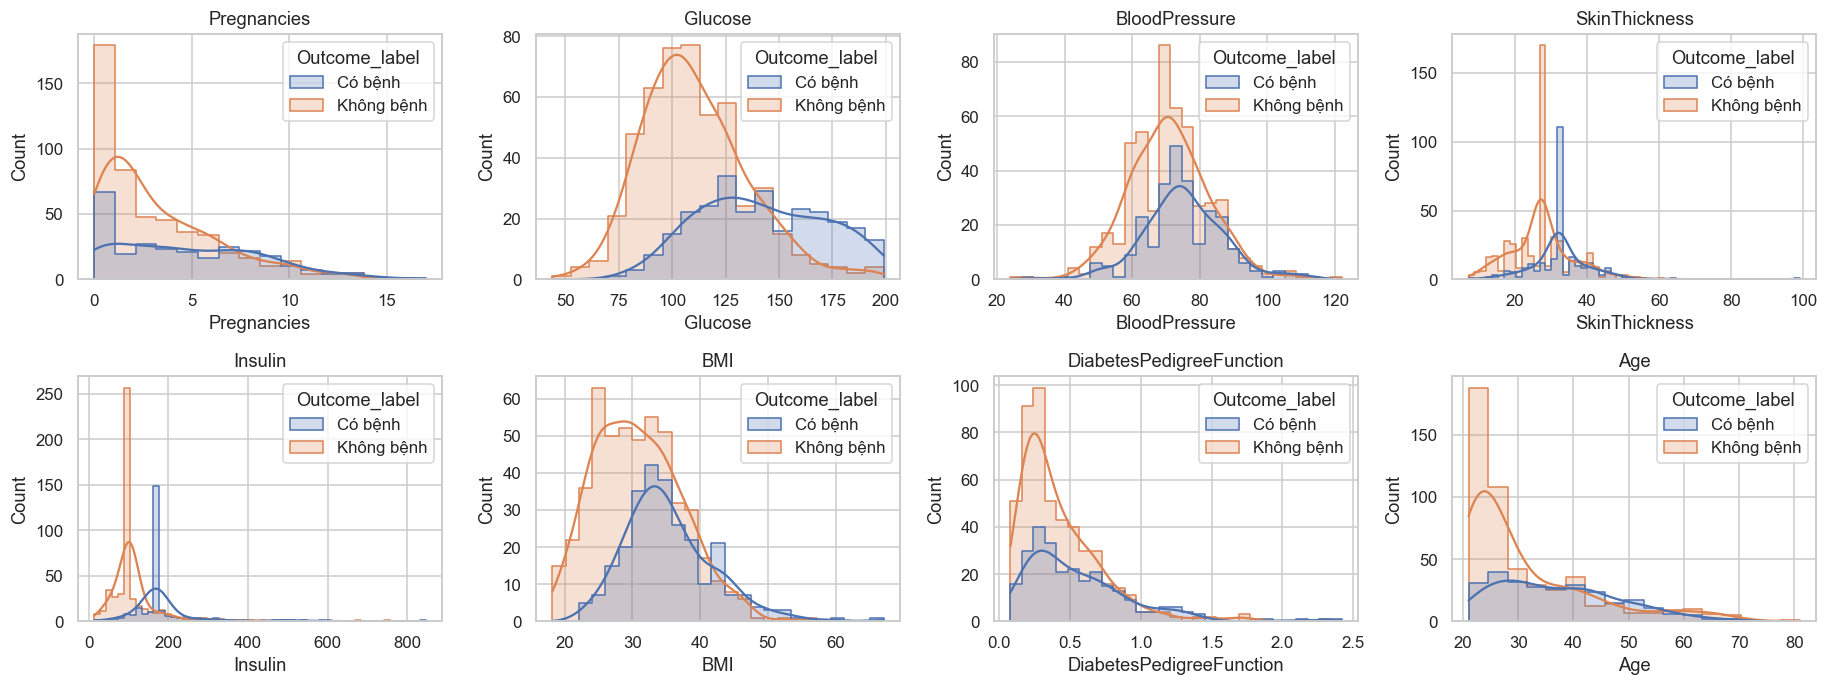

[Đã lưu] figures\s12_diabetes_hist.png


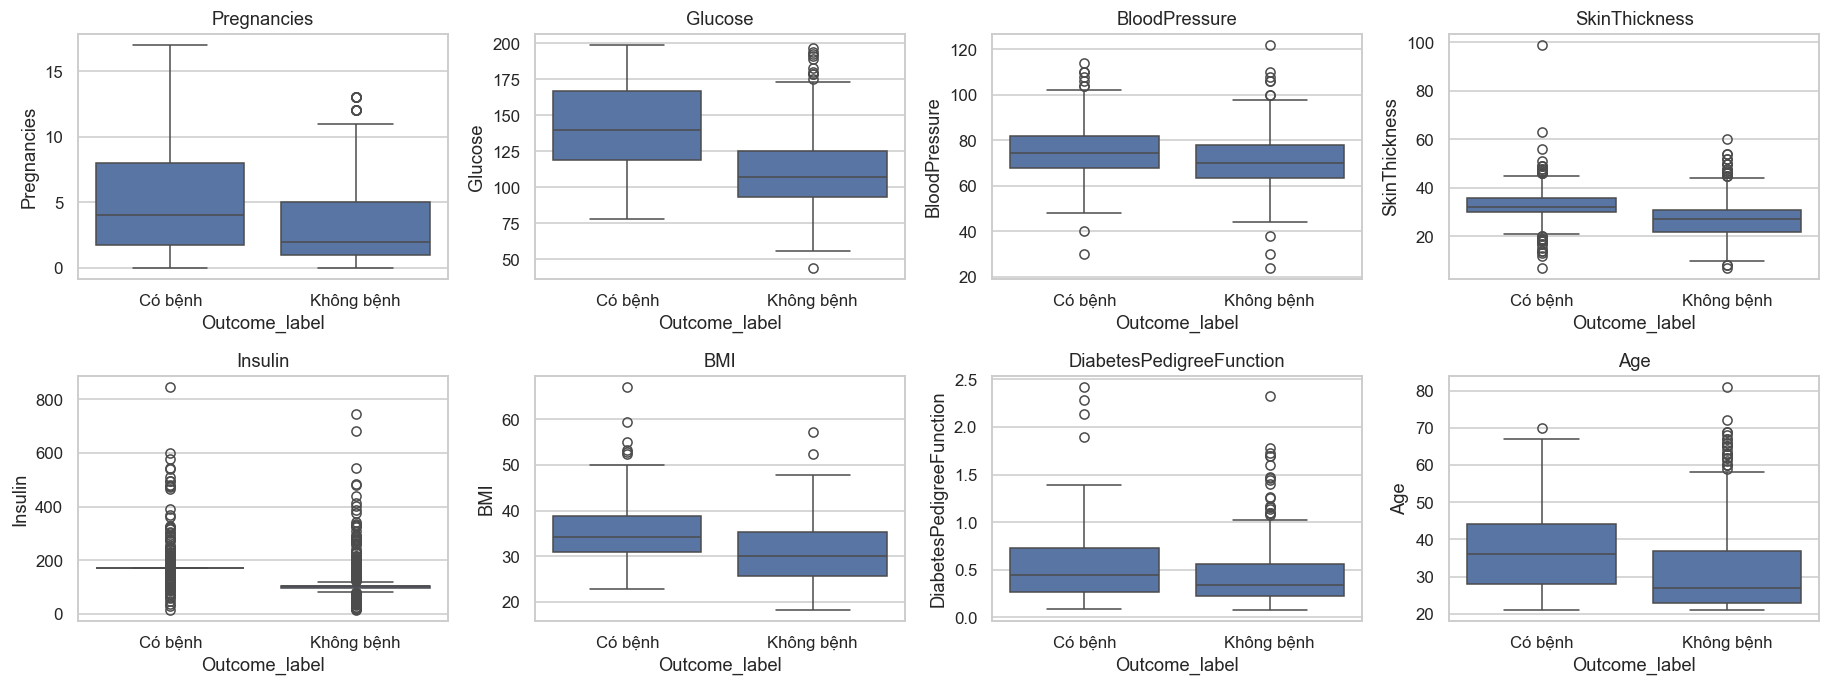

[Đã lưu] figures\s12_diabetes_box.png


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
sns.countplot(data=db, x="Outcome_label", ax=axs[0]); axs[0].set_title("Mất cân bằng lớp")
db["Outcome_label"].value_counts().plot.pie(autopct="%1.1f%%", ax=axs[1], ylabel="")
save_fig("s12_diabetes_outcome")

grid_plot(db, feat_db, kind="hist", ncols=4, hue="Outcome_label", name="s12_diabetes_hist")
grid_plot(db, feat_db, kind="box", ncols=4, hue="Outcome_label", name="s12_diabetes_box")

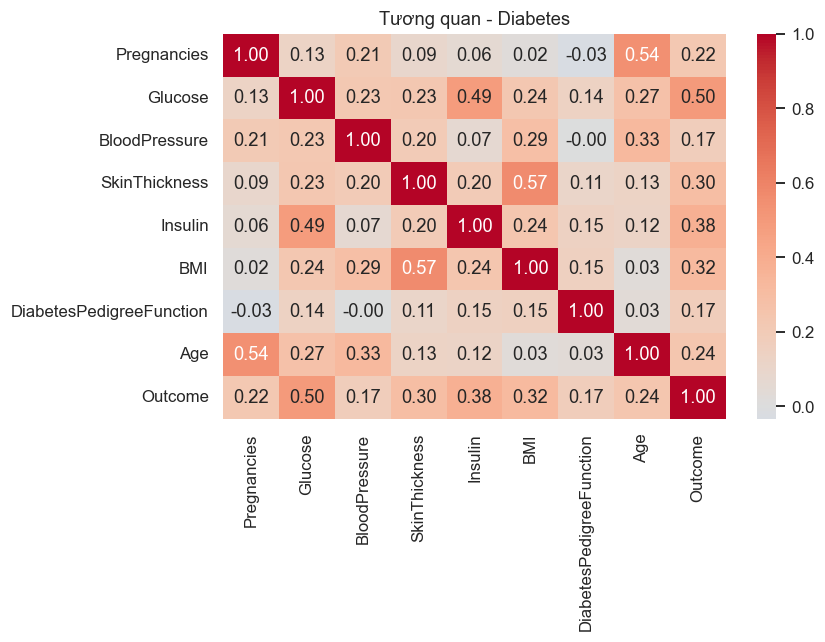

[Đã lưu] figures\s12_diabetes_corr.png


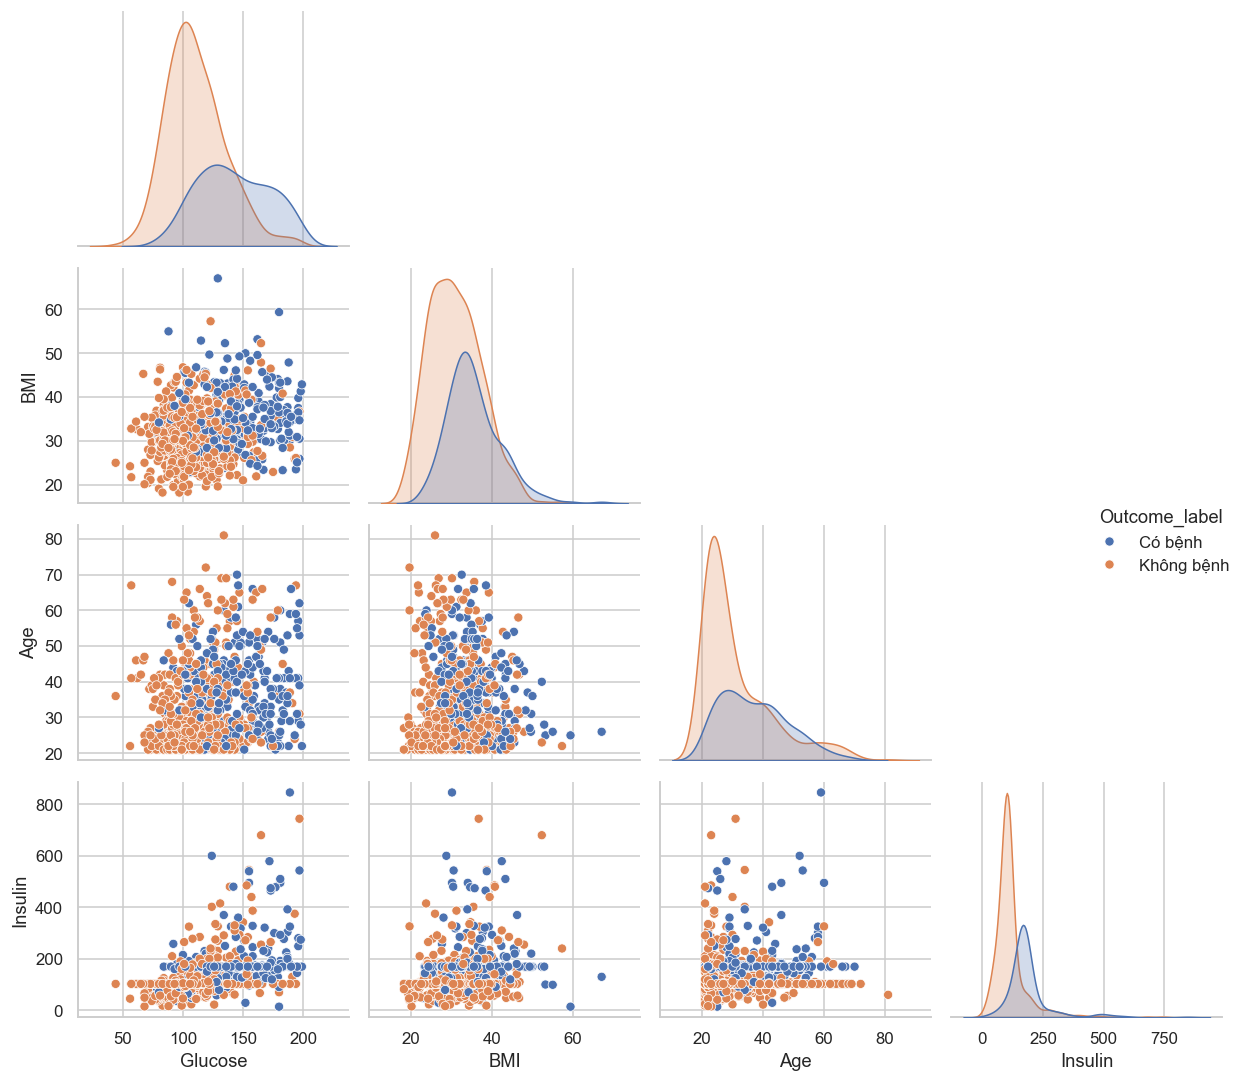

[Đã lưu] figures\s12_diabetes_pairplot.png


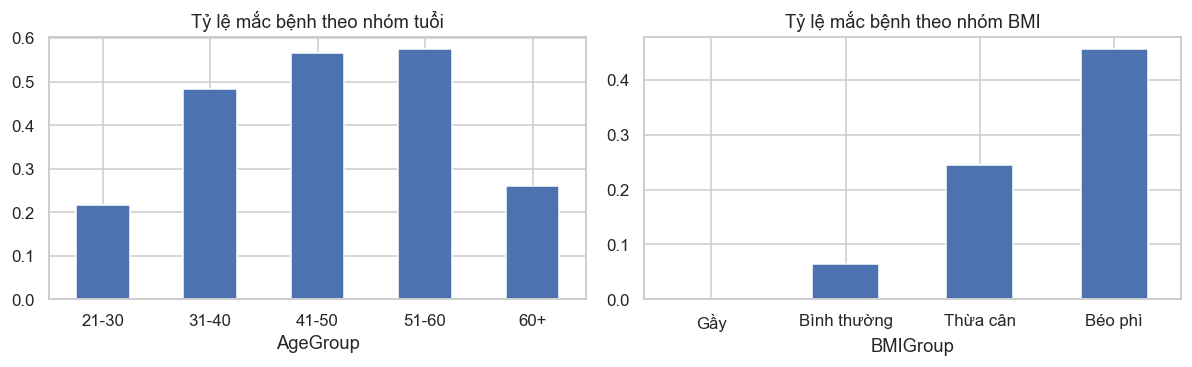

[Đã lưu] figures\s12_diabetes_rate_groups.png


In [14]:
corr = db[feat_db + [target]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Tương quan - Diabetes"); save_fig("s12_diabetes_corr")

sns.pairplot(db[["Glucose", "BMI", "Age", "Insulin", "Outcome_label"]], hue="Outcome_label", corner=True)
save_fig("s12_diabetes_pairplot")

# Tỷ lệ mắc bệnh theo nhóm tuổi / BMI
db["AgeGroup"] = pd.cut(db["Age"], [20, 30, 40, 50, 60, 100], labels=["21-30", "31-40", "41-50", "51-60", "60+"])
db["BMIGroup"] = pd.cut(db["BMI"], [0, 18.5, 25, 30, 100], labels=["Gầy", "Bình thường", "Thừa cân", "Béo phì"])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
db.groupby("AgeGroup")[target].mean().plot.bar(ax=axs[0], rot=0, title="Tỷ lệ mắc bệnh theo nhóm tuổi")
db.groupby("BMIGroup")[target].mean().plot.bar(ax=axs[1], rot=0, title="Tỷ lệ mắc bệnh theo nhóm BMI")
save_fig("s12_diabetes_rate_groups")

## D. Bài tập 2.2 - Online Retail: EDA

In [15]:
rt = load_table("OnlineRetail.csv", "Online Retail.xlsx", "online_retail*.csv", "online_retail*.xlsx", "*retail*.csv", "*retail*.xlsx")
rt = rt.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
rt["InvoiceDate"] = pd.to_datetime(rt["InvoiceDate"])
overview(rt, "Online Retail")

[Đọc dữ liệu] data\Online Retail.xlsx
===== Online Retail =====
Kích thước: 541909 dòng x 8 cột
Số dòng trùng lặp: 5268


,dtype,missing,missing_%,n_unique
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,object,0,0.00,38


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Làm sạch:** đơn hủy (InvoiceNo bắt đầu bằng 'C'), Quantity/UnitPrice <= 0, thiếu CustomerID

In [16]:
rt["InvoiceNo"] = rt["InvoiceNo"].astype(str)
rt["IsCancel"] = rt["InvoiceNo"].str.startswith("C")
print(f"Đơn hủy: {rt['IsCancel'].sum()} ({rt['IsCancel'].mean():.1%}) | Quantity <= 0: {(rt['Quantity'] <= 0).sum()} "
      f"| UnitPrice <= 0: {(rt['UnitPrice'] <= 0).sum()} | thiếu CustomerID: {rt['CustomerID'].isna().sum()}")

clean = rt[(~rt["IsCancel"]) & (rt["Quantity"] > 0) & (rt["UnitPrice"] > 0)].drop_duplicates().copy()
clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["Hour"] = clean["InvoiceDate"].dt.hour
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()
print("Sau làm sạch:", clean.shape)
display(describe_full(clean[["Quantity", "UnitPrice", "Revenue"]]))

Đơn hủy: 9288 (1.7%) | Quantity <= 0: 10624 | UnitPrice <= 0: 2517 | thiếu CustomerID: 135080
Sau làm sạch: (524878, 13)


,count,missing,mean,median,mode,std,var,min,max,range,Q1,Q3,IQR,skew,kurtosis
Quantity,524878,0,10.617,4.00,1.00,156.280,24423.448,1.000,80995.00,80994.000,1.00,11.00,10.00,469.542,234228.704
UnitPrice,524878,0,3.923,2.08,1.25,36.093,1302.707,0.001,13541.33,13541.329,1.25,4.13,2.88,205.085,61873.719
Revenue,524878,0,20.275,9.92,15.00,271.694,73817.394,0.001,168469.60,168469.599,3.90,17.70,13.80,504.233,294741.143


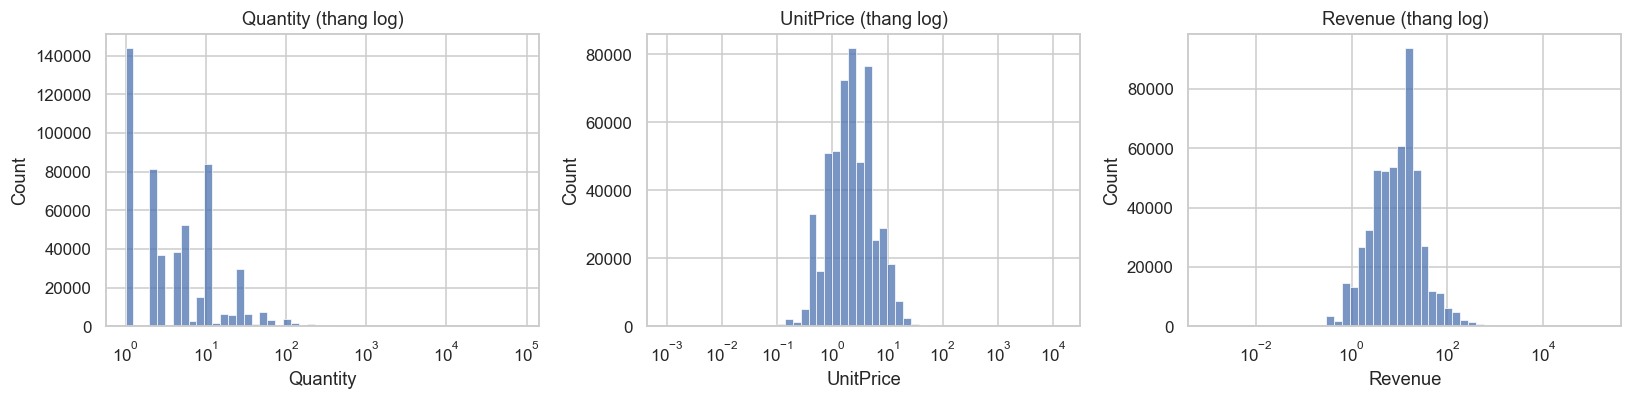

[Đã lưu] figures\s12_retail_dist.png


In [17]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axs, ["Quantity", "UnitPrice", "Revenue"]):
    sns.histplot(clean[c], log_scale=True, bins=50, ax=ax); ax.set_title(f"{c} (thang log)")
save_fig("s12_retail_dist")

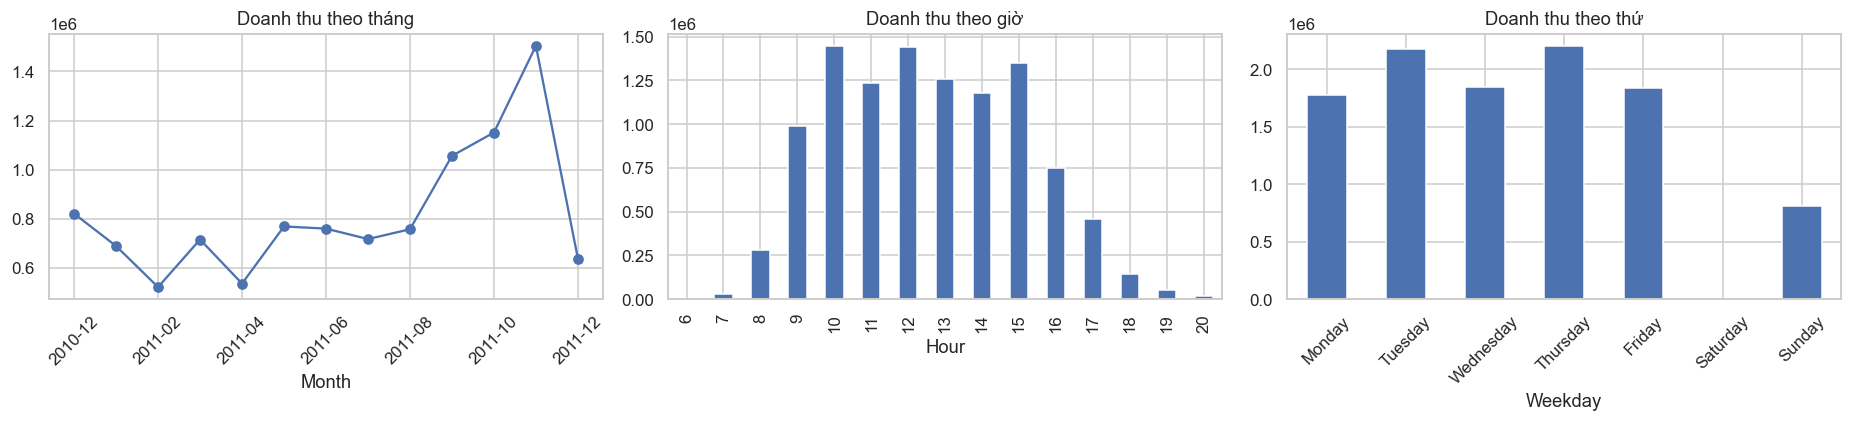

[Đã lưu] figures\s12_retail_time.png


In [18]:
# Doanh thu theo tháng, theo giờ, theo thứ
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
clean.groupby("Month")["Revenue"].sum().plot(marker="o", ax=axs[0], title="Doanh thu theo tháng", rot=45)
clean.groupby("Hour")["Revenue"].sum().plot.bar(ax=axs[1], title="Doanh thu theo giờ")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
clean.groupby("Weekday")["Revenue"].sum().reindex(order).plot.bar(ax=axs[2], title="Doanh thu theo thứ", rot=45)
save_fig("s12_retail_time")

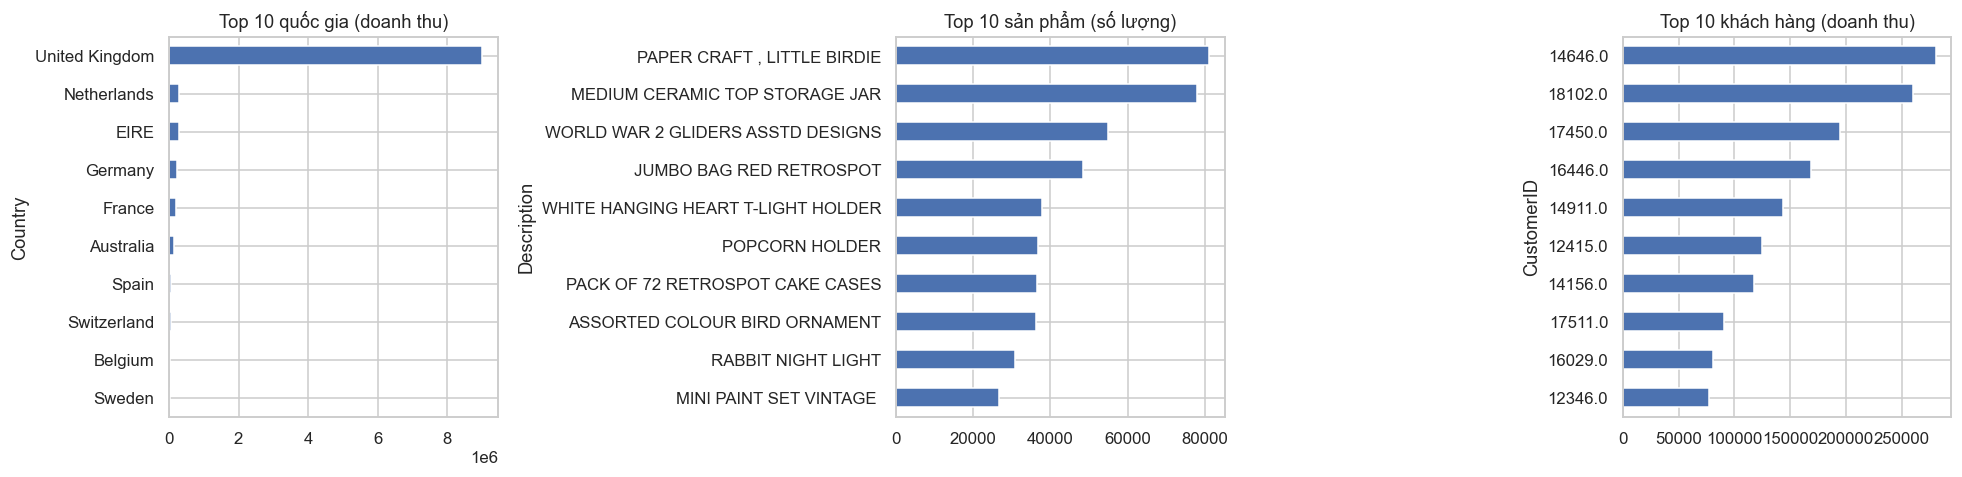

[Đã lưu] figures\s12_retail_top.png


In [19]:
# Quốc gia, sản phẩm, khách hàng hàng đầu
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
clean.groupby("Country")["Revenue"].sum().nlargest(10).sort_values().plot.barh(ax=axs[0], title="Top 10 quốc gia (doanh thu)")
clean.groupby("Description")["Quantity"].sum().nlargest(10).sort_values().plot.barh(ax=axs[1], title="Top 10 sản phẩm (số lượng)")
clean.dropna(subset=["CustomerID"]).groupby("CustomerID")["Revenue"].sum().nlargest(10).sort_values().plot.barh(ax=axs[2], title="Top 10 khách hàng (doanh thu)")
save_fig("s12_retail_top")

Số hóa đơn: 19960 | Số khách: 4338 | Giá trị đơn trung bình: 533.17 | median: 303.30


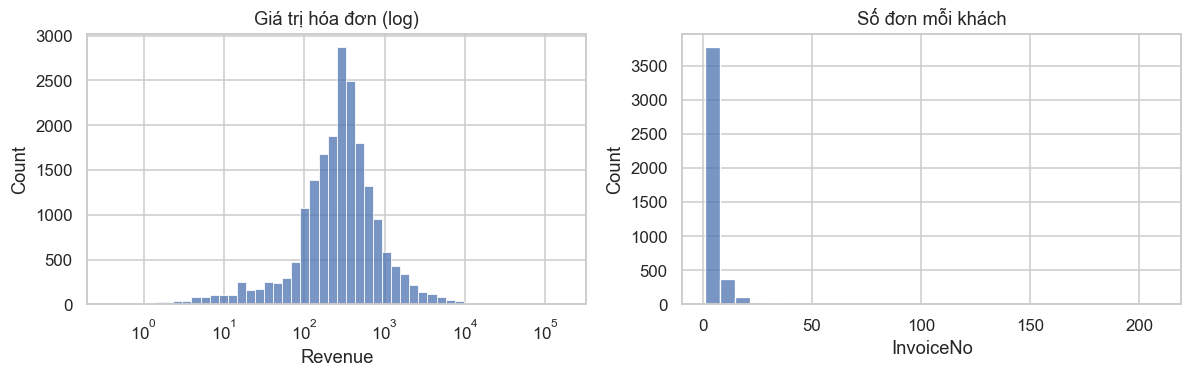

[Đã lưu] figures\s12_retail_invoice_customer.png


In [20]:
# Số đơn / khách, giá trị đơn hàng trung bình
inv = clean.groupby("InvoiceNo")["Revenue"].sum()
cust = clean.dropna(subset=["CustomerID"]).groupby("CustomerID")["InvoiceNo"].nunique()
print(f"Số hóa đơn: {inv.shape[0]} | Số khách: {cust.shape[0]} | Giá trị đơn trung bình: {inv.mean():.2f} | median: {inv.median():.2f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(inv, log_scale=True, bins=50, ax=axs[0]); axs[0].set_title("Giá trị hóa đơn (log)")
sns.histplot(cust, bins=30, ax=axs[1]); axs[1].set_title("Số đơn mỗi khách")
save_fig("s12_retail_invoice_customer")